https://www.digitalocean.com/community/tutorials/normalize-data-in-python

https://www.kaggle.com/datasets/simonezappatini/body-fat-extended-dataset

https://www.geeksforgeeks.org/detect-and-remove-the-outliers-using-python/

https://saturncloud.io/blog/how-to-detect-and-exclude-outliers-in-a-pandas-dataframe/

# **1. MOUNTING DRIVE**

In [4]:
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

root_path = "/content/drive/MyDrive/Colab Notebooks/Portofolio Data/"

print("Letak File: ", root_path)

Mounted at /content/drive
Letak File:  /content/drive/MyDrive/Colab Notebooks/Portofolio Data/


# **2. PREPROCESSING DATA**

## **2.1. Import Library**

In [5]:
# Library yang akan digunakan
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

## **2.2. Membaca Dataset**

In [6]:
df = pd.read_csv(root_path + "BodyFat - Extended.csv")

In [7]:
df

,BodyFat,Original,Sex,Age,Weight,Height,Neck,Chest,Abdomen,Hip,Thigh,Knee,Ankle,Biceps,Forearm,Wrist
0,12.30,Y,M,23,69.9700,1.7200,36.2,93.1,85.2,94.5,59.0,37.3,21.9,32.0,27.4,17.1
1,6.10,Y,M,22,78.5900,1.8400,38.5,93.6,83.0,98.7,58.7,37.3,23.4,30.5,28.9,18.2
2,25.30,Y,M,22,69.8500,1.6800,34.0,95.8,87.9,99.2,59.6,38.9,24.0,28.8,25.2,16.6
3,10.40,Y,M,26,83.8000,1.8400,37.4,101.8,86.4,101.2,60.1,37.3,22.8,32.4,29.4,18.2
4,28.70,Y,M,24,83.5800,1.8100,34.4,97.3,100.0,101.9,63.2,42.2,24.0,32.2,27.7,17.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
431,30.40,N,F,23,59.8752,1.5621,31.3,89.0,71.0,98.5,56.0,36.2,21.0,28.0,24.5,16.3
432,7.47,N,F,21,48.5352,1.5748,29.5,79.0,62.5,89.0,49.0,33.0,20.0,25.0,22.0,15.5
433,11.98,N,F,20,51.7104,1.5748,31.5,81.5,61.5,90.0,49.5,32.0,19.5,27.5,22.5,15.0
434,11.24,N,F,22,50.8032,1.6510,30.5,85.0,64.0,88.0,45.0,32.0,19.5,24.0,21.5,15.0


## **2.3. Cek Outliers(Opsional)**

### **2.3.1. Visualisasi Outliers**

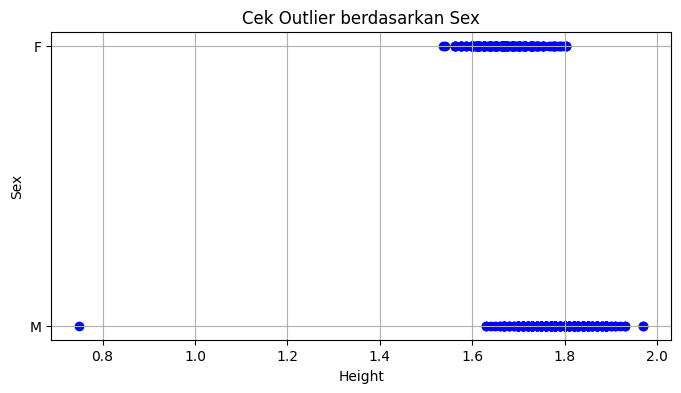

In [8]:
x = df['Height']
y = df['Sex']

fig, ax = plt.subplots(figsize = (8,4))

ax.scatter(x, y, color="blue")
plt.title('Cek Outlier berdasarkan Sex')

ax.set_xlabel('Height')
ax.set_ylabel('Sex')

plt.grid(True)
plt.show()

### **2.3.2. Normalisasi Data**

In [9]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

scaler = MinMaxScaler(feature_range=(0,1))
columns_to_normalize = ['Weight',	'Height',	'Neck',	'Chest',	'Abdomen',	'Hip'	,'Thigh', 'Knee', 'Ankle',	'Biceps',	'Forearm',	'Wrist']
df[columns_to_normalize] = scaler.fit_transform(df[columns_to_normalize])

df

,BodyFat,Original,Sex,Age,Weight,Height,Neck,Chest,Abdomen,Hip,Thigh,Knee,Ankle,Biceps,Forearm,Wrist
0,12.30,Y,M,23,0.226753,0.795082,0.404762,0.537554,0.301887,0.184049,0.425963,0.516393,0.245283,0.469388,0.496644,0.455696
1,6.10,Y,M,22,0.297100,0.893443,0.496032,0.542918,0.277469,0.248466,0.419878,0.516393,0.339623,0.408163,0.597315,0.594937
2,25.30,Y,M,22,0.225773,0.762295,0.317460,0.566524,0.331853,0.256135,0.438134,0.581967,0.377358,0.338776,0.348993,0.392405
3,10.40,Y,M,26,0.339618,0.893443,0.452381,0.630901,0.315205,0.286810,0.448276,0.516393,0.301887,0.485714,0.630872,0.594937
4,28.70,Y,M,24,0.337823,0.868852,0.333333,0.582618,0.466149,0.297546,0.511156,0.717213,0.377358,0.477551,0.516779,0.531646
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
431,30.40,N,F,23,0.144370,0.665656,0.210317,0.493562,0.144284,0.245399,0.365112,0.471311,0.188679,0.306122,0.302013,0.354430
432,7.47,N,F,21,0.051825,0.676066,0.138889,0.386266,0.049945,0.099693,0.223124,0.340164,0.125786,0.183673,0.134228,0.253165
433,11.98,N,F,20,0.077738,0.676066,0.218254,0.413090,0.038846,0.115031,0.233266,0.299180,0.094340,0.285714,0.167785,0.189873
434,11.24,N,F,22,0.070334,0.738525,0.178571,0.450644,0.066593,0.084356,0.141988,0.299180,0.094340,0.142857,0.100671,0.189873


### **2.3.3. Proses Outliers**

In [10]:
def outliers(text):
  from scipy import stats
  z = np.abs(stats.zscore(text))

  threshold = 3
  outliers = df[z > threshold]

  # Calculate IQR for Column
  Q1 = text.quantile(0.25)
  Q3 = text.quantile(0.75)
  IQR = Q3 - Q1

  # Identifikasi Outlier
  threshold = 1.5
  outliers = df[(text < Q1 - threshold * IQR) | (text > Q3 + threshold * IQR)]
  # teks = df.drop(outliers.index)
  return outliers

In [11]:
outliers(df['Height'])

median_height = df['Height'].median()

df['Height'].replace(0.0, median_height, inplace=True)

# x = df['Height']
# y = df['Sex']

# fig, ax = plt.subplots(figsize = (8,4))

# ax.scatter(x, y, color="blue")
# plt.title('Cek Outlier Hubungan Height dengan Gender')

# ax.set_xlabel('Height')
# ax.set_ylabel('Sex')

# plt.grid(True)
# plt.show()

/tmp/ipykernel_752/803608962.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Height'].replace(0.0, median_height, inplace=True)


In [12]:
outliers(df['Weight'])

median_weight = df['Weight'].median()

df.loc[df["Weight"] >= 0.62, "Weight"] = median_weight

# x = df['Weight']
# y = df['Sex']

# fig, ax = plt.subplots(figsize = (8,4))

# ax.scatter(x, y, color="blue")
# plt.title('Cek Outlier Hubungan Weight dengan Gender')

# ax.set_xlabel('Weight')
# ax.set_ylabel('Sex')

# plt.grid(True)
# plt.show()

In [13]:
# outliers(df['Neck'])

# median_neck = df['Neck'].median()

# df.loc[df['Neck'] == 1.0, 'Neck'] = median_neck

# x = df['Neck']
# y = df['Sex']

# fig, ax = plt.subplots(figsize = (8,4))

# ax.scatter(x, y, color="blue")
# plt.title('Cek Outlier Hubungan Neck dengan Gender')

# ax.set_xlabel('Weight')
# ax.set_ylabel('Sex')

# plt.grid(True)
# plt.show()

In [14]:
outliers(df['Chest'])

median_chest = df['Chest'].median()

df.loc[df['Chest'] >= 0.91, 'Chest'] = median_chest
df.loc[df['Chest'] <= 0.07, 'Chest'] = median_chest


# x = df['Chest']
# y = df['Sex']

# fig, ax = plt.subplots(figsize = (8,4))

# ax.scatter(x, y, color="blue")
# plt.title('Cek Outlier Hubungan Chest dengan Gender')

# ax.set_xlabel('Weight')
# ax.set_ylabel('Sex')

# plt.grid(True)
# plt.show()

In [15]:
outliers(df['Abdomen'])

median_abdomen = df['Abdomen'].median()

df.loc[df['Abdomen'] == 1.0, 'Abdomen'] = median_abdomen
# outliers(df['Abdomen'])

In [16]:
outliers(df['Hip'])

median_hip = df['Hip'].median()
df.loc[df['Hip'] >=0.50, 'Hip'] = median_hip

# print(outliers(df['Hip']))

# x = df['Hip']
# y = df['Sex']

# fig, ax = plt.subplots(figsize = (8,4))

# ax.scatter(x, y, color="blue")
# plt.title('Cek Outlier')

# ax.set_xlabel('Weight')
# ax.set_ylabel('Sex')

# plt.grid(True)
# plt.show()

Empty DataFrame
Columns: [BodyFat, Original, Sex, Age, Weight, Height, Neck, Chest, Abdomen, Hip, Thigh, Knee, Ankle, Biceps, Forearm, Wrist]
Index: []


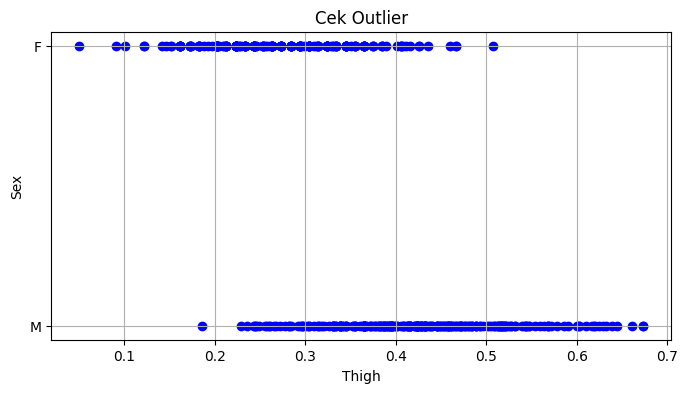

In [17]:
outliers(df['Thigh'])

median_thigh = df['Thigh'].median()
df.loc[df['Thigh'] >= 0.69, 'Thigh'] = median_thigh
df.loc[df['Thigh'] == 0.0, 'Thigh'] = median_thigh

print(outliers(df['Thigh']))

x = df['Thigh']
y = df['Sex']

fig, ax = plt.subplots(figsize = (8,4))

ax.scatter(x, y, color="blue")
plt.title('Cek Outlier')

ax.set_xlabel('Thigh')
ax.set_ylabel('Sex')

plt.grid(True)
plt.show()

Empty DataFrame
Columns: [BodyFat, Original, Sex, Age, Weight, Height, Neck, Chest, Abdomen, Hip, Thigh, Knee, Ankle, Biceps, Forearm, Wrist]
Index: []


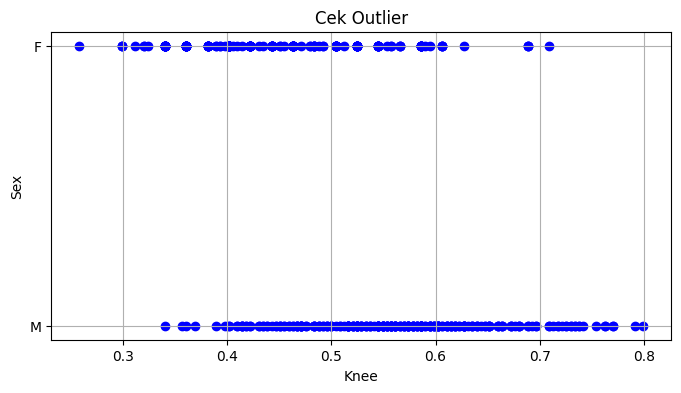

In [18]:
outliers(df['Knee'])

median_knee = df['Knee'].median()
df.loc[df['Knee'] >= 0.83, 'Knee'] = median_knee
df.loc[df['Knee'] == 0.0, 'Knee'] = median_knee

print(outliers(df['Knee']))

x = df['Knee']
y = df['Sex']

fig, ax = plt.subplots(figsize = (8,4))

ax.scatter(x, y, color="blue")
plt.title('Cek Outlier')

ax.set_xlabel('Knee')
ax.set_ylabel('Sex')

plt.grid(True)
plt.show()

Empty DataFrame
Columns: [BodyFat, Original, Sex, Age, Weight, Height, Neck, Chest, Abdomen, Hip, Thigh, Knee, Ankle, Biceps, Forearm, Wrist]
Index: []


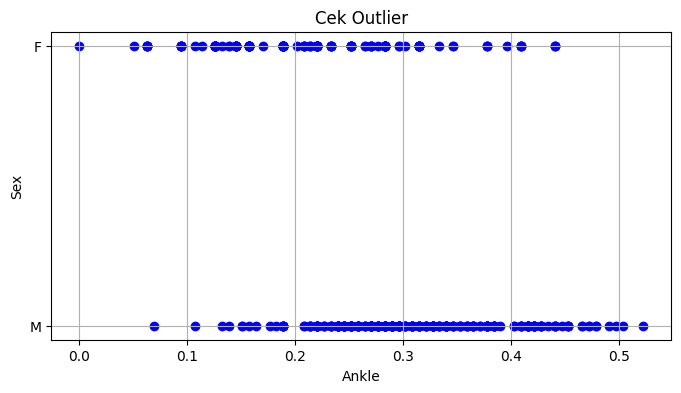

In [19]:
outliers(df['Ankle'])

median_ankle = df['Ankle'].median()

df.loc[df['Ankle'] >= 0.54, 'Ankle'] = median_ankle

print(outliers(df['Ankle']))

x = df['Ankle']
y = df['Sex']

fig, ax = plt.subplots(figsize = (8,4))

ax.scatter(x, y, color="blue")
plt.title('Cek Outlier')

ax.set_xlabel('Ankle')
ax.set_ylabel('Sex')

plt.grid(True)
plt.show()

0.3795918367346939
Empty DataFrame
Columns: [BodyFat, Original, Sex, Age, Weight, Height, Neck, Chest, Abdomen, Hip, Thigh, Knee, Ankle, Biceps, Forearm, Wrist]
Index: []


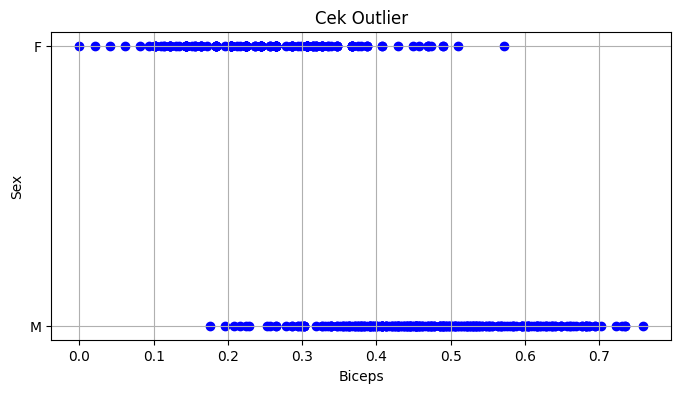

In [20]:
outliers(df['Biceps'])

median_biceps = df['Biceps'].median()

print(median_biceps)
df.loc[df['Biceps'] >= 0.99, 'Biceps'] = median_biceps

print(outliers(df['Biceps']))

x = df['Biceps']
y = df['Sex']

fig, ax = plt.subplots(figsize = (8,4))

ax.scatter(x, y, color="blue")
plt.title('Cek Outlier')

ax.set_xlabel('Biceps')
ax.set_ylabel('Sex')

plt.grid(True)
plt.show()

In [21]:
# outliers(df['Forearm'])
# outliers(df['Wrist'])

## **2.4. Merubah Atributes BodyFat menjadi kelas**

In [22]:
min_body = df['BodyFat'].min()
max_body = df['BodyFat'].max()
avg_body = df['BodyFat'].mean()
median_body = df['BodyFat'].median()

print('Nilai minimumn body fat: ', min_body)
print('Nilai maksimum body fat: ', max_body)
print('Nilai rerata body fat: ', avg_body)
print('Nilai median body fat: ', median_body)

Nilai minimumn body fat:  0.0
Nilai maksimum body fat:  47.5
Nilai rerata body fat:  20.249839449541284
Nilai median body fat:  20.5


step selanjutnya, merubah nilai body fat menjadi variable yang di labelkan. Label tersebut berdasarkan jurnal: https://media.neliti.com/media/publications/412027-a-design-of-body-mass-index-bmi-and-body-bf304d12.pdf

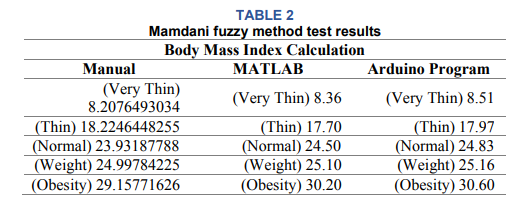

In [23]:
def category_bodyfat(teks):
  kategori = ''

  if teks < 18.23:
    kategori = 'Very Thin'
  elif teks > 18.23 and teks <= 23.99:
    kategori = 'Thin'
  elif teks > 23.99 and teks <= 24.99:
    kategori = 'Normal'
  elif teks > 24.99  and teks < 29.15:
    kategori = 'Weight'
  elif teks >= 29.15:
    kategori = 'Obesitas'
  return kategori

In [24]:
df['KategoriFat'] = df['BodyFat'].apply(category_bodyfat)

# df.drop(['Kategori Fat'], axis=1, inplace = True)
df

,BodyFat,Original,Sex,Age,Weight,Height,Neck,Chest,Abdomen,Hip,Thigh,Knee,Ankle,Biceps,Forearm,Wrist,KategoriFat
0,12.30,Y,M,23,0.226753,0.795082,0.404762,0.537554,0.301887,0.184049,0.425963,0.516393,0.245283,0.469388,0.496644,0.455696,Very Thin
1,6.10,Y,M,22,0.297100,0.893443,0.496032,0.542918,0.277469,0.248466,0.419878,0.516393,0.339623,0.408163,0.597315,0.594937,Very Thin
2,25.30,Y,M,22,0.225773,0.762295,0.317460,0.566524,0.331853,0.256135,0.438134,0.581967,0.377358,0.338776,0.348993,0.392405,Weight
3,10.40,Y,M,26,0.339618,0.893443,0.452381,0.630901,0.315205,0.286810,0.448276,0.516393,0.301887,0.485714,0.630872,0.594937,Very Thin
4,28.70,Y,M,24,0.337823,0.868852,0.333333,0.582618,0.466149,0.297546,0.511156,0.717213,0.377358,0.477551,0.516779,0.531646,Weight
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
431,30.40,N,F,23,0.144370,0.665656,0.210317,0.493562,0.144284,0.245399,0.365112,0.471311,0.188679,0.306122,0.302013,0.354430,Obesitas
432,7.47,N,F,21,0.051825,0.676066,0.138889,0.386266,0.049945,0.099693,0.223124,0.340164,0.125786,0.183673,0.134228,0.253165,Very Thin
433,11.98,N,F,20,0.077738,0.676066,0.218254,0.413090,0.038846,0.115031,0.233266,0.299180,0.094340,0.285714,0.167785,0.189873,Very Thin
434,11.24,N,F,22,0.070334,0.738525,0.178571,0.450644,0.066593,0.084356,0.141988,0.299180,0.094340,0.142857,0.100671,0.189873,Very Thin


In [25]:
df.shape

(436, 17)

In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 436 entries, 0 to 435
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   BodyFat      436 non-null    float64
 1   Original     436 non-null    object 
 2   Sex          436 non-null    object 
 3   Age          436 non-null    int64  
 4   Weight       436 non-null    float64
 5   Height       436 non-null    float64
 6   Neck         436 non-null    float64
 7   Chest        436 non-null    float64
 8   Abdomen      436 non-null    float64
 9   Hip          436 non-null    float64
 10  Thigh        436 non-null    float64
 11  Knee         436 non-null    float64
 12  Ankle        436 non-null    float64
 13  Biceps       436 non-null    float64
 14  Forearm      436 non-null    float64
 15  Wrist        436 non-null    float64
 16  KategoriFat  436 non-null    object 
dtypes: float64(13), int64(1), object(3)
memory usage: 58.0+ KB


In [27]:
df.isnull().sum()

,0
BodyFat,0
Original,0
Sex,0
Age,0
Weight,0
Height,0
Neck,0
Chest,0
Abdomen,0
Hip,0


In [28]:
# Import label encoder
from sklearn import preprocessing

# label_encoder object knows
# how to understand word labels.
label = preprocessing.LabelEncoder()

# Encode labels in column 'species'.
df['Original']= label.fit_transform(df['Original'])
df['Sex']= label.fit_transform(df['Sex'])
# print(label.classes_)

df

,BodyFat,Original,Sex,Age,Weight,Height,Neck,Chest,Abdomen,Hip,Thigh,Knee,Ankle,Biceps,Forearm,Wrist,KategoriFat
0,12.30,1,1,23,0.226753,0.795082,0.404762,0.537554,0.301887,0.184049,0.425963,0.516393,0.245283,0.469388,0.496644,0.455696,Very Thin
1,6.10,1,1,22,0.297100,0.893443,0.496032,0.542918,0.277469,0.248466,0.419878,0.516393,0.339623,0.408163,0.597315,0.594937,Very Thin
2,25.30,1,1,22,0.225773,0.762295,0.317460,0.566524,0.331853,0.256135,0.438134,0.581967,0.377358,0.338776,0.348993,0.392405,Weight
3,10.40,1,1,26,0.339618,0.893443,0.452381,0.630901,0.315205,0.286810,0.448276,0.516393,0.301887,0.485714,0.630872,0.594937,Very Thin
4,28.70,1,1,24,0.337823,0.868852,0.333333,0.582618,0.466149,0.297546,0.511156,0.717213,0.377358,0.477551,0.516779,0.531646,Weight
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
431,30.40,0,0,23,0.144370,0.665656,0.210317,0.493562,0.144284,0.245399,0.365112,0.471311,0.188679,0.306122,0.302013,0.354430,Obesitas
432,7.47,0,0,21,0.051825,0.676066,0.138889,0.386266,0.049945,0.099693,0.223124,0.340164,0.125786,0.183673,0.134228,0.253165,Very Thin
433,11.98,0,0,20,0.077738,0.676066,0.218254,0.413090,0.038846,0.115031,0.233266,0.299180,0.094340,0.285714,0.167785,0.189873,Very Thin
434,11.24,0,0,22,0.070334,0.738525,0.178571,0.450644,0.066593,0.084356,0.141988,0.299180,0.094340,0.142857,0.100671,0.189873,Very Thin


In [29]:
def konversi_kategoriFat(teks):
  konversi = 0

  if teks == 'Very Thin':
    konversi = 0
  elif teks == 'Thin':
    konversi = 1
  elif teks == 'Normal':
    konversi = 2
  elif teks == 'Weight':
    konversi = 3
  elif teks == 'Obesitas':
    konversi = 4
  return konversi

In [30]:
df['LabelFat'] = df['KategoriFat'].apply(konversi_kategoriFat)

df

,BodyFat,Original,Sex,Age,Weight,Height,Neck,Chest,Abdomen,Hip,Thigh,Knee,Ankle,Biceps,Forearm,Wrist,KategoriFat,LabelFat
0,12.30,1,1,23,0.226753,0.795082,0.404762,0.537554,0.301887,0.184049,0.425963,0.516393,0.245283,0.469388,0.496644,0.455696,Very Thin,0
1,6.10,1,1,22,0.297100,0.893443,0.496032,0.542918,0.277469,0.248466,0.419878,0.516393,0.339623,0.408163,0.597315,0.594937,Very Thin,0
2,25.30,1,1,22,0.225773,0.762295,0.317460,0.566524,0.331853,0.256135,0.438134,0.581967,0.377358,0.338776,0.348993,0.392405,Weight,3
3,10.40,1,1,26,0.339618,0.893443,0.452381,0.630901,0.315205,0.286810,0.448276,0.516393,0.301887,0.485714,0.630872,0.594937,Very Thin,0
4,28.70,1,1,24,0.337823,0.868852,0.333333,0.582618,0.466149,0.297546,0.511156,0.717213,0.377358,0.477551,0.516779,0.531646,Weight,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
431,30.40,0,0,23,0.144370,0.665656,0.210317,0.493562,0.144284,0.245399,0.365112,0.471311,0.188679,0.306122,0.302013,0.354430,Obesitas,4
432,7.47,0,0,21,0.051825,0.676066,0.138889,0.386266,0.049945,0.099693,0.223124,0.340164,0.125786,0.183673,0.134228,0.253165,Very Thin,0
433,11.98,0,0,20,0.077738,0.676066,0.218254,0.413090,0.038846,0.115031,0.233266,0.299180,0.094340,0.285714,0.167785,0.189873,Very Thin,0
434,11.24,0,0,22,0.070334,0.738525,0.178571,0.450644,0.066593,0.084356,0.141988,0.299180,0.094340,0.142857,0.100671,0.189873,Very Thin,0


In [31]:
df = df.drop('KategoriFat', axis=1) # KategoriFat needs to be a string

df.corr()

,BodyFat,Original,Sex,Age,Weight,Height,Neck,Chest,Abdomen,Hip,Thigh,Knee,Ankle,Biceps,Forearm,Wrist,LabelFat
BodyFat,1.000000,-0.171641,-0.171641,0.015808,0.321469,-0.127768,0.121790,0.305245,0.345048,0.573761,0.295370,0.337936,0.177771,0.244738,0.106236,0.089182,0.893557
Original,-0.171641,1.000000,1.000000,0.781513,0.691341,0.677581,0.836811,0.732595,0.788301,0.200075,0.646837,0.521295,0.523602,0.710263,0.810138,0.806997,-0.073583
Sex,-0.171641,1.000000,1.000000,0.781513,0.691341,0.677581,0.836811,0.732595,0.788301,0.200075,0.646837,0.521295,0.523602,0.710263,0.810138,0.806997,-0.073583
Age,0.015808,0.781513,0.781513,1.000000,0.533069,0.441159,0.685648,0.641352,0.694631,0.130097,0.429989,0.399272,0.334614,0.537460,0.605983,0.687237,0.081129
Weight,0.321469,0.691341,0.691341,0.533069,1.000000,0.728166,0.862300,0.928962,0.918620,0.766198,0.888223,0.852174,0.779557,0.884341,0.855803,0.840719,0.353466
Height,-0.127768,0.677581,0.677581,0.441159,0.728166,1.000000,0.683166,0.606806,0.610928,0.408401,0.595445,0.606284,0.590470,0.595043,0.664902,0.673802,-0.089797
Neck,0.121790,0.836811,0.836811,0.685648,0.862300,0.683166,1.000000,0.865591,0.883077,0.497445,0.776197,0.689888,0.657581,0.841550,0.881829,0.899204,0.184816
Chest,0.305245,0.732595,0.732595,0.641352,0.928962,0.606806,0.865591,1.000000,0.926577,0.643462,0.813342,0.745859,0.673185,0.853599,0.834973,0.823684,0.338106
Abdomen,0.345048,0.788301,0.788301,0.694631,0.918620,0.610928,0.883077,0.926577,1.000000,0.627137,0.823109,0.759651,0.663241,0.854449,0.846173,0.848089,0.384436
Hip,0.573761,0.200075,0.200075,0.130097,0.766198,0.408401,0.497445,0.643462,0.627137,1.000000,0.721908,0.757472,0.633310,0.628947,0.522177,0.502325,0.554700


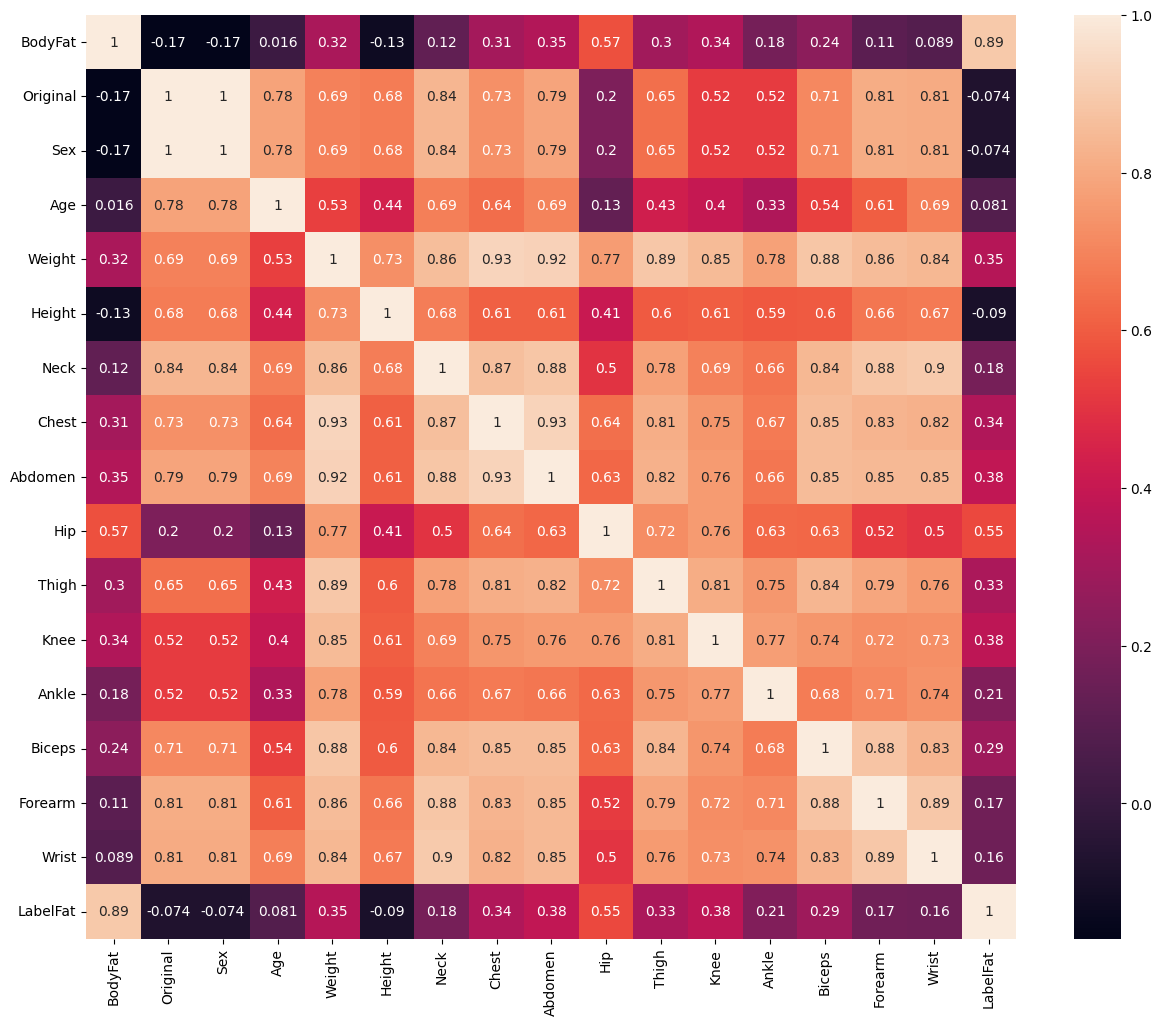

In [32]:
corr_matrix = df.corr()

plt.subplots(figsize = (15,12))
sns.heatmap(corr_matrix, annot=True)
plt.show()

In [33]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import sklearn.metrics as metrics

In [34]:
attributs = ['Wrist', 'Forearm', 'Biceps', 'Ankle', 'Knee', 'Thigh', 'Hip', 'Abdomen', 'Chest', 'Neck', 'Weight']
target = ['LabelFat']

In [35]:
X = df[attributs]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.1, random_state=42)

In [36]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((392, 11), (44, 11), (392, 1), (44, 1))

In [37]:
model = DecisionTreeClassifier()

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
score = accuracy_score(y_test, y_pred)

print("Model Skor Akurasi: ", score)
print("Model Akurasi dibulatkan: ", round(score, 3)) # Membulatkan 3 angka dibelakang koma

Model Skor Akurasi:  0.5227272727272727
Model Akurasi dibulatkan:  0.523


              precision    recall  f1-score   support

           0       0.56      0.88      0.68        16
           1       0.70      0.37      0.48        19
           2       0.20      0.50      0.29         2
           3       0.00      0.00      0.00         3
           4       1.00      0.25      0.40         4

    accuracy                           0.52        44
   macro avg       0.49      0.40      0.37        44
weighted avg       0.61      0.52      0.51        44



Confusion matrix

 [[14  2  0  0  0]
 [ 8  7  2  2  0]
 [ 1  0  1  0  0]
 [ 1  1  1  0  0]
 [ 1  0  1  1  1]]


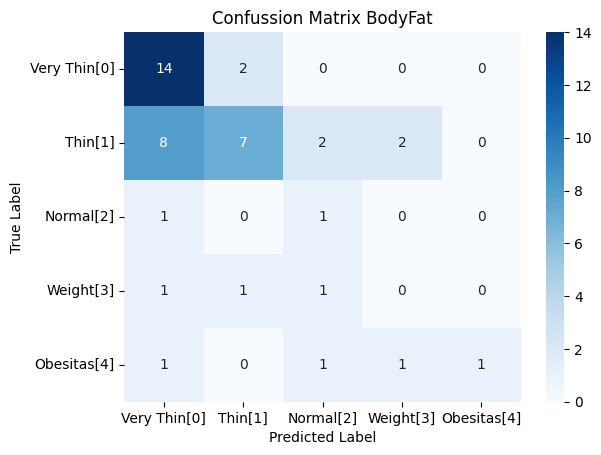

In [38]:
from sklearn.metrics import confusion_matrix, classification_report

print(classification_report(y_test, y_pred))
print("\n")
labels = ['Very Thin[0]', 'Thin[1]', 'Normal[2]', 'Weight[3]', 'Obesitas[4]']

cm = confusion_matrix(y_test, y_pred)
print('Confusion matrix\n\n', cm)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confussion Matrix BodyFat')
plt.show()

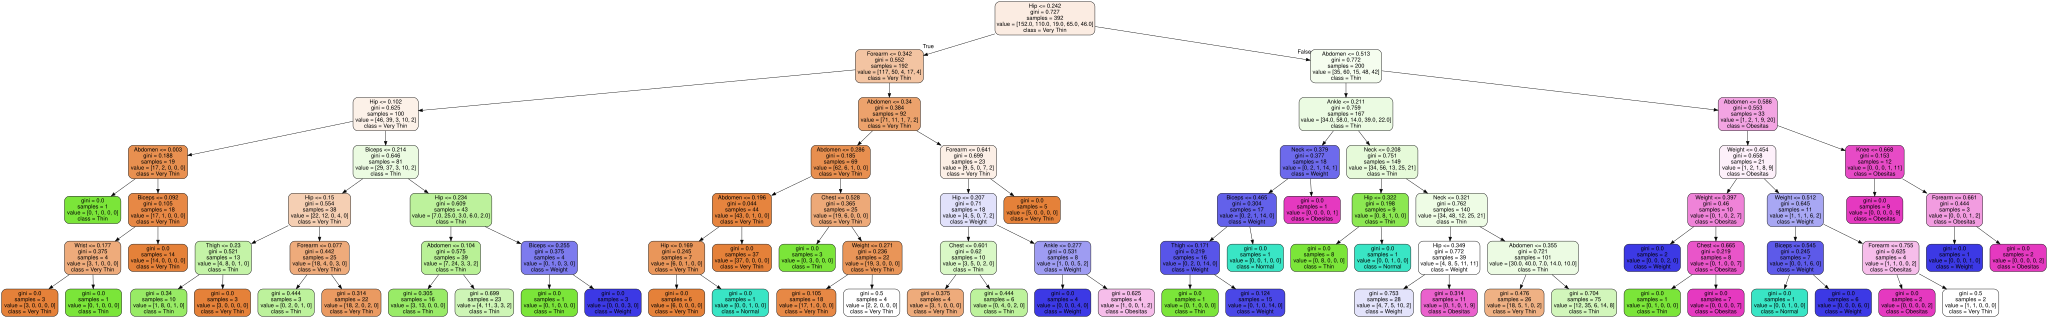

In [41]:
import graphviz
from sklearn import tree
from sklearn.tree import plot_tree

clf = DecisionTreeClassifier(max_depth = 6)
clf=clf.fit(X_train, y_train)

dt_feature_names = list(X.columns)

# Menggunakan list manual kembali
dt_target_names = ['Very Thin', 'Thin', 'Normal', 'Weight', 'Obesitas']

dot_data = tree.export_graphviz(clf, out_file=None,
                                feature_names = dt_feature_names,
                                class_names = dt_target_names,
                                filled = True, rounded = True)

graph = graphviz.Source(dot_data)
graph.render('BodyFat')

graph